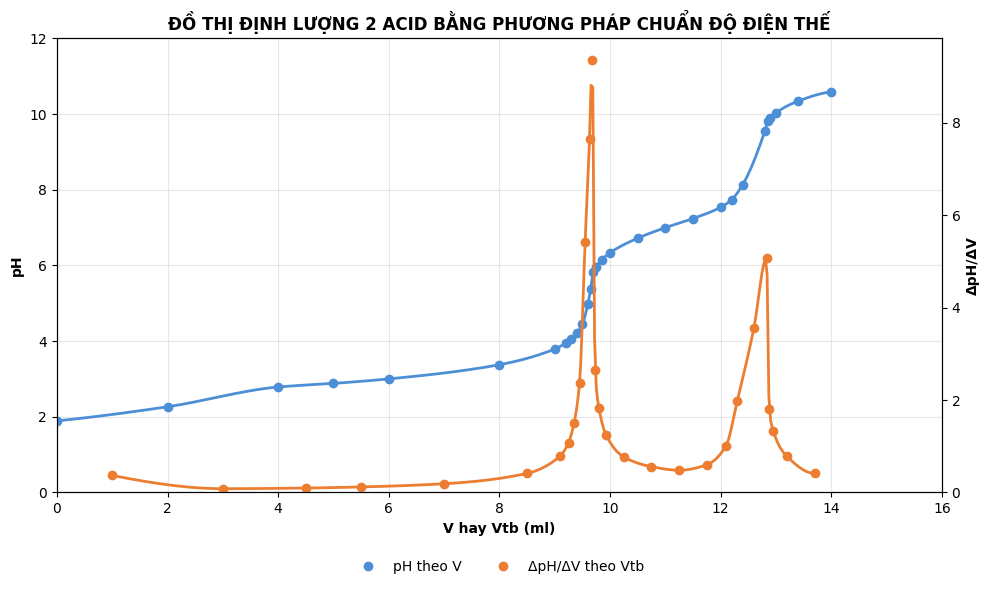

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

df = pd.read_csv("TH HPT1.csv", decimal=",")

titr  = df.dropna(subset=["V_NaOH", "pH"])[["V_NaOH", "pH"]]
deriv = df.dropna(subset=["V_tb", "ΔpH/ΔV"])[["V_tb", "ΔpH/ΔV"]]

def smooth(x, y, n=400):
    xs = np.linspace(x.min(), x.max(), n)
    return xs, PchipInterpolator(x, y)(xs)

x1, y1 = smooth(titr["V_NaOH"].values, titr["pH"].values)
x2, y2 = smooth(deriv["V_tb"].values,  deriv["ΔpH/ΔV"].values)

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(x1, y1, color="#4C8FD6", lw=2)
ax1.plot(titr["V_NaOH"], titr["pH"], "o", color="#4C8FD6", label="pH theo V")
ax1.set_xlabel("V hay Vtb (ml)", fontweight="bold")
ax1.set_ylabel("pH", fontweight="bold")
ax1.set_xlim(0, titr["V_NaOH"].max() + 2)
ax1.set_ylim(0, 12)

ax2 = ax1.twinx()
ax2.plot(x2, y2, color="#ED7D31", lw=2)
ax2.plot(deriv["V_tb"], deriv["ΔpH/ΔV"], "o", color="#ED7D31", label="ΔpH/ΔV theo Vtb")
ax2.set_ylabel("ΔpH/ΔV", fontweight="bold")
ax2.set_ylim(bottom=0)

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper center",
           bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)

ax1.set_title("ĐỒ THỊ ĐỊNH LƯỢNG 2 ACID BẰNG PHƯƠNG PHÁP CHUẨN ĐỘ ĐIỆN THẾ", fontweight="bold")

ax1.grid(alpha=0.3)
plt.tight_layout()
plt.show()